# 02 · Modelado, selección, umbral, calibración y explicabilidad

Cubre los puntos **3.5 (modelos y selección)**, **3.6 (generalización)** y **3.7 (métricas)**
del enunciado, a partir de las decisiones del notebook 01:

- conjunto principal **sin E09**;
- evaluación principal: **entrenar con todo lo anterior a octubre y probar con octubre**, también
  solo con clientes nuevos;
- generalización a negocios nuevos: **dejar fuera una empresa a la vez**;
- todo **con y sin `ai_chars_mean`**, que en el EDA resultó ser una huella de la empresa.

Al final se guarda el modelo desplegable en `models/` y las métricas que usa `model_card.md`.

In [1]:
import os, sys, json, time, warnings
os.environ["PYTHONWARNINGS"] = "ignore"   # silence joblib worker warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, shap
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, learning_curve
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             recall_score, precision_score, brier_score_loss, confusion_matrix)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import load, build_features, time_split, TARGET, DOMINANT
from risk_model import (DROP, make_rf, group_splits, calibrated, shift_prior, estimate_prior_em,
                        threshold_for_recall, RiskModel, explain, train_risk_model)

warnings.filterwarnings("ignore")
FIG = ROOT / "figures"; MODELS = ROOT / "models"; FIG.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
C0, C1, C2, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#8a8984"
sns.set_theme(style="white", rc={"axes.edgecolor": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                                 "figure.dpi": 110, "font.size": 10})
def save(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)
RNG = 0

df = load(ROOT / "data" / "orvyz_conversaciones_riesgo.csv")
rest = df[df.empresa != DOMINANT].reset_index(drop=True)
tr, te = time_split(rest)
new_cust = ~te.cliente.isin(set(tr.cliente)).values
VARIANTS = {"con ai_chars_mean": (), "sin ai_chars_mean": DROP}
y_tr, y_te = tr[TARGET].values, te[TARGET].values
print(f"Entrenamiento {len(tr):,} (pos {y_tr.mean():.0%}) | octubre {len(te):,} (pos {y_te.mean():.0%}) | "
      f"octubre solo clientes nuevos {new_cust.sum():,} (pos {y_te[new_cust].mean():.0%})")

Entrenamiento 2,806 (pos 65%) | octubre 2,465 (pos 44%) | octubre solo clientes nuevos 1,577 (pos 54%)


## 1. Modelos candidatos y búsqueda de hiperparámetros

- **Líneas base:** predecir siempre la clase mayoritaria, y regresión logística (lineal, interpretable).
- **Candidatos:** kNN, SVM con kernel RBF, árbol de decisión, Random Forest y Gradient Boosting
  (`HistGradientBoostingClassifier`).
- **Preprocesamiento dentro del `Pipeline`:** imputación con la mediana y, para logística, kNN y SVM,
  escalado estándar. Se ajusta en cada pliegue solo con su parte de entrenamiento.
- **Búsqueda aleatoria** de 20 combinaciones por modelo, con `StratifiedGroupKFold` de 5 pliegues
  **agrupado por cliente**, optimizando **PR-AUC** (la métrica principal, ver sección 5).
- `class_weight="balanced"` donde aplica. La probabilidad se recalibra después.

In [2]:
imp = lambda: SimpleImputer(strategy="median")
CANDIDATOS = {
    "Mayoritaria": (DummyClassifier(strategy="prior"), None),
    "Logística": (make_pipeline(imp(), StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
                  {"logisticregression__C": loguniform(1e-3, 1e2)}),
    "kNN": (make_pipeline(imp(), StandardScaler(), KNeighborsClassifier()),
            {"kneighborsclassifier__n_neighbors": randint(5, 150), "kneighborsclassifier__weights": ["uniform", "distance"]}),
    "SVM": (make_pipeline(imp(), StandardScaler(), SVC(class_weight="balanced")),
            {"svc__C": loguniform(1e-2, 1e2), "svc__gamma": loguniform(1e-4, 1e0)}),
    "Árbol": (make_pipeline(imp(), DecisionTreeClassifier(class_weight="balanced", random_state=RNG)),
              {"decisiontreeclassifier__max_depth": randint(2, 12), "decisiontreeclassifier__min_samples_leaf": randint(5, 100)}),
    "Random Forest": (make_rf(), {"rf__max_depth": [4, 6, 8, 12, None], "rf__min_samples_leaf": randint(1, 40),
                                  "rf__max_features": uniform(0.1, 0.6)}),
    "Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=RNG),
                          {"learning_rate": loguniform(0.01, 0.3), "max_depth": [2, 3, 4, 6, None],
                           "min_samples_leaf": randint(10, 200), "l2_regularization": loguniform(1e-3, 10),
                           "max_iter": randint(100, 500)}),
}
def score(m, X): return m.predict_proba(X)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X)
cv = StratifiedGroupKFold(5, shuffle=True, random_state=RNG)

In [3]:
def leave_one_company_out(est, drop):
    X_all = build_features(rest, drop); out = []
    for e in sorted(rest.empresa.unique()):
        m = (rest.empresa == e).values
        if rest[TARGET][m].nunique() < 2: continue
        fit = clone(est).fit(X_all[~m], rest[TARGET][~m])
        out.append(pd.DataFrame({"y": rest[TARGET][m].values, "p": score(fit, X_all[m]), "empresa": e}))
    return pd.concat(out)

resultados, mejores, logo = [], {}, {}
for variante, drop in VARIANTS.items():
    Xtr, Xte = build_features(tr, drop), build_features(te, drop)
    for nombre, (est, grid) in CANDIDATOS.items():
        t0 = time.time()
        if grid is None:
            best = clone(est).fit(Xtr, y_tr); cv_mean, cv_std, params = np.nan, np.nan, {}
        else:
            s = RandomizedSearchCV(est, grid, n_iter=20, cv=cv, scoring="average_precision", n_jobs=-1,
                                   random_state=RNG).fit(Xtr, y_tr, groups=tr.cliente)
            best, params = s.best_estimator_, s.best_params_
            cv_mean, cv_std = s.best_score_, s.cv_results_["std_test_score"][s.best_index_]
        p = score(best, Xte)
        lo = leave_one_company_out(best, drop) if grid is not None else None
        mejores[(variante, nombre)], logo[(variante, nombre)] = best, lo
        resultados.append({
            "variante": variante, "modelo": nombre, "PR-AUC CV": cv_mean, "± CV": cv_std,
            "ROC-AUC oct": roc_auc_score(y_te, p), "PR-AUC oct": average_precision_score(y_te, p),
            "ROC-AUC oct nuevos": roc_auc_score(y_te[new_cust], p[new_cust]),
            "ROC-AUC empresas no vistas": roc_auc_score(lo.y, lo.p) if lo is not None else np.nan,
            "ROC-AUC medio por empresa": np.mean([roc_auc_score(g.y, g.p) for _, g in lo.groupby("empresa")]) if lo is not None else np.nan,
            "seg": round(time.time() - t0), "params": params})
R = pd.DataFrame(resultados)
R.drop(columns="params").set_index(["variante", "modelo"]).round(3)

PR-AUC CV   ± CV  ROC-AUC oct  \
variante          modelo                                             
con ai_chars_mean Mayoritaria              NaN    NaN        0.500   
                  Logística              0.831  0.013        0.777   
                  kNN                    0.845  0.014        0.699   
                  SVM                    0.851  0.007        0.763   
                  Árbol                  0.847  0.014        0.790   
                  Random Forest          0.886  0.010        0.808   
                  Gradient Boosting      0.878  0.003        0.813   
sin ai_chars_mean Mayoritaria              NaN    NaN        0.500   
                  Logística              0.830  0.015        0.753   
                  kNN                    0.838  0.017        0.684   
                  SVM                    0.837  0.012        0.736   
                  Árbol                  0.838  0.015        0.758   
                  Random Forest          0.872  0.015        0.786   
                  Gradient Boosting      0.866  0.010        0.790   

                                     PR-AUC oct  ROC-AUC oct nuevos  \
variante          modelo                                              
con ai_chars_mean Mayoritaria             0.445               0.500   
                  Logística               0.731               0.716   
                  kNN                     0.634               0.618   
                  SVM                     0.734               0.725   
                  Árbol                   0.753               0.741   
                  Random Forest           0.795               0.765   
                  Gradient Boosting       0.796               0.765   
sin ai_chars_mean Mayoritaria             0.445               0.500   
                  Logística               0.704               0.672   
                  kNN                     0.624               0.612   
                  SVM                     0.688               0.663   
                  Árbol                   0.712               0.708   
                  Random Forest           0.771               0.736   
                  Gradient Boosting       0.772               0.733   

                                     ROC-AUC empresas no vistas  \
variante          modelo                                          
con ai_chars_mean Mayoritaria                               NaN   
                  Logística                               0.702   
                  kNN                                     0.544   
                  SVM                                     0.672   
                  Árbol                                   0.687   
                  Random Forest                           0.706   
                  Gradient Boosting                       0.679   
sin ai_chars_mean Mayoritaria                               NaN   
                  Logística                               0.653   
                  kNN                                     0.504   
                  SVM                                     0.623   
                  Árbol                                   0.526   
                  Random Forest                           0.694   
                  Gradient Boosting                       0.679   

                                     ROC-AUC medio por empresa  seg  
variante          modelo                                             
con ai_chars_mean Mayoritaria                              NaN    0  
                  Logística                              0.637    3  
                  kNN                                    0.605    1  
                  SVM                                    0.641    7  
                  Árbol                                  0.585    1  
                  Random Forest                          0.631   18  
                  Gradient Boosting                      0.625   20  
sin ai_chars_mean Mayoritaria                              NaN    0  
      

**Cómo leer la tabla.**
- *PR-AUC CV*: validación cruzada dentro del entrenamiento (hasta septiembre), agrupada por cliente. Es la
  que guía la búsqueda.
- *Octubre*: prueba temporal, el resultado principal. El azar en PR-AUC es la proporción de
  positivos de octubre (0,44).
- *Octubre nuevos*: solo clientes que no aparecen en el entrenamiento.
- *Empresas no vistas*: cada empresa se predice con un modelo entrenado sin ella, y se juntan las
  predicciones.
- *Medio por empresa*: el AUC calculado dentro de cada empresa y promediado. Mide si el modelo
  **ordena bien las conversaciones de un mismo negocio**, que es lo que necesita la cola de
  atención.

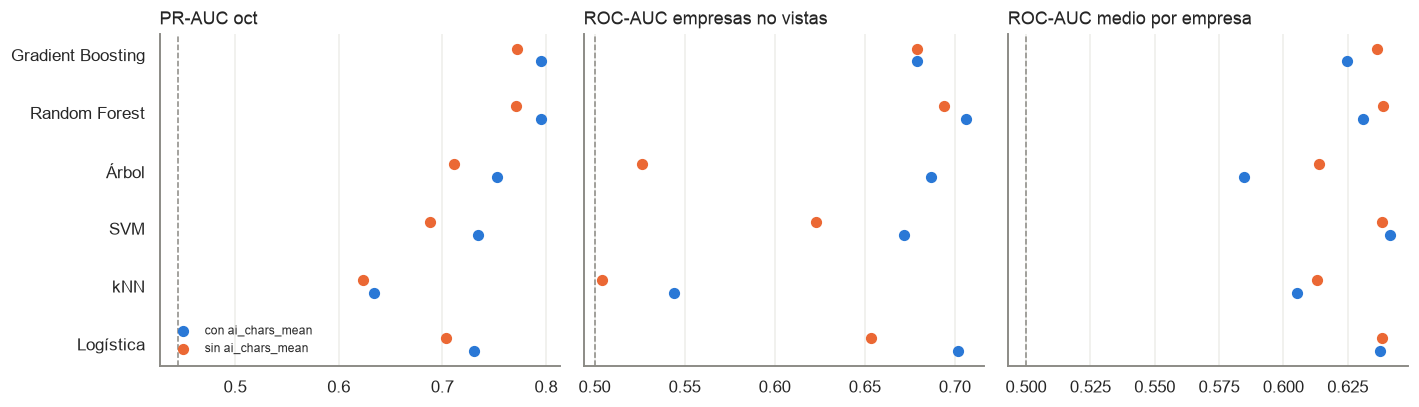

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
orden = [m for m in CANDIDATOS if m != "Mayoritaria"]
for ax, col, ref in zip(axs, ["PR-AUC oct", "ROC-AUC empresas no vistas", "ROC-AUC medio por empresa"],
                        [y_te.mean(), 0.5, 0.5]):
    for i, (v, c) in enumerate(zip(VARIANTS, [C0, C1])):
        s = R[R.variante == v].set_index("modelo").loc[orden, col]
        ax.scatter(s.values, np.arange(len(orden)) + (i - 0.5) * 0.22, color=c, s=40, label=v, zorder=3)
    ax.axvline(ref, color=MUTED, ls="--", lw=1); ax.set_title(col, loc="left")
    ax.set_yticks(range(len(orden)), orden); ax.grid(axis="x", color="#eeede9")
axs[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout(); save(fig, "10_comparacion_modelos"); plt.show()

## 2. Selección del modelo

In [5]:
sin = R[R.variante == "sin ai_chars_mean"].set_index("modelo")
con = R[R.variante == "con ai_chars_mean"].set_index("modelo")
print("Efecto de quitar ai_chars_mean (sin − con):")
print((sin[["PR-AUC oct", "ROC-AUC oct", "ROC-AUC empresas no vistas", "ROC-AUC medio por empresa"]]
       - con[["PR-AUC oct", "ROC-AUC oct", "ROC-AUC empresas no vistas", "ROC-AUC medio por empresa"]]).drop("Mayoritaria").round(3))
ELEGIDO = ("sin ai_chars_mean", "Random Forest")
best_params = {k.replace("rf__", ""): v for k, v in R.set_index(["variante", "modelo"]).loc[ELEGIDO, "params"].items()}
best_params = {k: (float(v) if isinstance(v, (np.floating, float)) else (int(v) if isinstance(v, (np.integer,)) else v))
               for k, v in best_params.items()}
json.dump(best_params, open(MODELS / "best_params.json", "w"), indent=2)
print("\nElegido:", ELEGIDO, best_params)

Efecto de quitar ai_chars_mean (sin − con):
                   PR-AUC oct  ROC-AUC oct  ROC-AUC empresas no vistas  \
modelo                                                                   
Logística              -0.027       -0.023                      -0.048   
kNN                    -0.010       -0.015                      -0.040   
SVM                    -0.047       -0.027                      -0.049   
Árbol                  -0.041       -0.032                      -0.161   
Random Forest          -0.024       -0.022                      -0.012   
Gradient Boosting      -0.024       -0.023                      -0.000   

                   ROC-AUC medio por empresa  
modelo                                        
Logística                              0.001  
kNN                                    0.008  
SVM                                   -0.003  
Árbol                                  0.029  
Random Forest                          0.008  
Gradient Boosting                 

**Criterio:** PR-AUC en octubre, estabilidad entre empresas y que no dependa de la huella de la empresa.

- **Random Forest y Gradient Boosting ganan en la prueba de octubre y con empresas no vistas.**
  kNN es el peor: con variables de escalas y naturalezas distintas, la distancia no representa bien
  la similitud entre conversaciones. El árbol simple se desploma con empresas no vistas
  (sobreajusta a las empresas que conoce).
- **Dentro de cada empresa, todos los modelos empatan** (AUC medio ≈ 0,64, salvo kNN y el árbol).
  Ese techo lo ponen las variables, no el algoritmo: con 4 mensajes, sin texto y con señales
  escasas, hay poca información para distinguir conversaciones de un mismo negocio.
- **Quitar `ai_chars_mean` cuesta unos 0,02 de PR-AUC en octubre**, porque en octubre las empresas son
  las mismas y la huella ayuda a reconocerlas. **Dentro de cada empresa no cambia nada.** El modelo
  desplegado tiene que servir a negocios nuevos y no debe castigar a una empresa por el estilo de
  su bot, así que **se despliega la versión sin ella**.
- Entre Random Forest y Gradient Boosting la diferencia en octubre es mínima. **Random Forest** se
  elige por ser algo más estable cuando la empresa no se vio en el entrenamiento.
- La validación cruzada (≈ 0,87) da más que octubre (≈ 0,77): mezcla meses y empresas en
  entrenamiento y validación, mientras que octubre trae cambio de mezcla. Por eso la evaluación que
  se reporta es la temporal.

### Escenario secundario: todas las empresas (con E09)
Mismo modelo y mismos hiperparámetros, entrenado y probado con E09 adentro, solo para comparar.

In [6]:
tr_all, te_all = time_split(df)
m_all = make_rf(**best_params).fit(build_features(tr_all, DROP), tr_all[TARGET])
p_all = m_all.predict_proba(build_features(te_all, DROP))[:, 1]
print(f"Con E09: ROC-AUC {roc_auc_score(te_all[TARGET], p_all):.3f} | PR-AUC {average_precision_score(te_all[TARGET], p_all):.3f} "
      f"(azar {te_all[TARGET].mean():.3f})")
for nombre, g in [("E09", te_all.empresa == DOMINANT), ("resto", te_all.empresa != DOMINANT)]:
    print(f"   solo {nombre}: ROC-AUC {roc_auc_score(te_all[TARGET][g], p_all[g.values]):.3f}")

Con E09: ROC-AUC 0.861 | PR-AUC 0.971 (azar 0.887)
   solo E09: ROC-AUC 0.683
   solo resto: ROC-AUC 0.740


Con E09 la PR-AUC se ve muy alta, pero el azar ya está cerca de 0,9: el número refleja la
proporción de positivos de E09, no capacidad de anticipar. Confirma la decisión del EDA de no
usar este escenario para elegir.

## 3. Curvas de aprendizaje

Random Forest: brecha final entrenamiento − validación = 0.076, validación 0.794 → 0.872


Logística: brecha final entrenamiento − validación = 0.013, validación 0.792 → 0.830


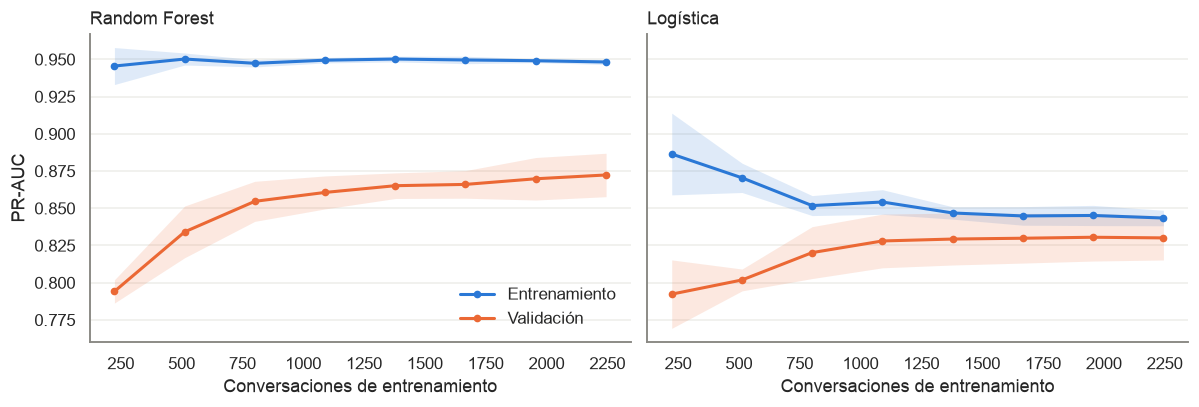

In [7]:
Xtr_f = build_features(tr, DROP)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (nombre, est) in zip(axs, [("Random Forest", make_rf(**best_params)),
                                    ("Logística", mejores[("sin ai_chars_mean", "Logística")])]):
    sizes, tr_sc, va_sc = learning_curve(est, Xtr_f, y_tr, groups=tr.cliente, cv=cv, scoring="average_precision",
                                         train_sizes=np.linspace(0.1, 1, 8), n_jobs=-1, shuffle=True, random_state=RNG)
    for sc, c, lab in [(tr_sc, C0, "Entrenamiento"), (va_sc, C1, "Validación")]:
        ax.plot(sizes, sc.mean(1), color=c, lw=2, marker="o", ms=4, label=lab)
        ax.fill_between(sizes, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), color=c, alpha=.15, lw=0)
    ax.set_title(nombre, loc="left"); ax.set_xlabel("Conversaciones de entrenamiento"); ax.grid(axis="y", color="#eeede9")
    print(f"{nombre}: brecha final entrenamiento − validación = {tr_sc.mean(1)[-1] - va_sc.mean(1)[-1]:.3f}, "
          f"validación {va_sc.mean(1)[0]:.3f} → {va_sc.mean(1)[-1]:.3f}")
axs[0].set_ylabel("PR-AUC"); axs[0].legend(frameon=False)
fig.tight_layout(); save(fig, "11_curvas_aprendizaje"); plt.show()

- **Random Forest:** hay una brecha entre entrenamiento y validación, esperable en un bosque con
  hojas pequeñas. Pero la validación **sigue subiendo** con más datos y su variación entre pliegues
  es baja: no hay un sobreajuste que dañe la generalización, y más datos (más meses, más empresas)
  deberían seguir mejorando el modelo. Esto respalda el reentrenamiento periódico de la sección 3.9.
- **Logística:** las dos curvas casi se tocan. El modelo está limitado por su forma lineal, no por
  falta de datos.

## 4. Calibración y punto de corte

Se usa el Random Forest elegido con **calibración isotónica**, ajustada con pliegues agrupados por
cliente. Para elegir el punto de corte sin mirar octubre, se generan predicciones **fuera de
pliegue** en el entrenamiento (validación cruzada anidada: cada conversación se predice con un
modelo, y una calibración, que no la vio).

Se definen dos umbrales sobre esa probabilidad:
- **Alerta (rojo):** el más alto que todavía detecta **al menos el 80 %** de los casos que van a
  necesitar persona. Entre los que cumplen esa meta, es el de mayor precisión.
- **Vigilar (amarillo):** el que detecta el 95 %.

¿Por qué 80 %? Dejar pasar un caso que se complica cuesta más que una alerta de más, pero
alertar casi todo cansa al asesor. La meta es un parámetro de negocio y se puede mover.

In [8]:
rf_base = make_rf(**best_params)
oof = np.zeros(len(tr))
for a, b in group_splits(Xtr_f, y_tr, tr.cliente.values, seed=1):
    cal = calibrated(rf_base, Xtr_f.iloc[a], y_tr[a], tr.cliente.values[a])
    oof[b] = cal.predict_proba(Xtr_f.iloc[b])[:, 1]
T_ALERTA, T_VIGILAR = threshold_for_recall(y_tr, oof, 0.80), threshold_for_recall(y_tr, oof, 0.95)
print(f"Fuera de pliegue (jul–sep): PR-AUC {average_precision_score(y_tr, oof):.3f} | Brier {brier_score_loss(y_tr, oof):.3f}")
print(f"Umbral de alerta {T_ALERTA:.3f} → recall {recall_score(y_tr, oof >= T_ALERTA):.2f}, precisión {precision_score(y_tr, oof >= T_ALERTA):.2f}")
print(f"Umbral de vigilancia {T_VIGILAR:.3f} → recall {recall_score(y_tr, oof >= T_VIGILAR):.2f}, precisión {precision_score(y_tr, oof >= T_VIGILAR):.2f}")

modelo_cal = calibrated(rf_base, Xtr_f, y_tr, tr.cliente.values)       # final model for the October test
rf_sin_cal = clone(rf_base).fit(Xtr_f, y_tr)
Xte_f = build_features(te, DROP)
p_cal, p_raw = modelo_cal.predict_proba(Xte_f)[:, 1], rf_sin_cal.predict_proba(Xte_f)[:, 1]
PRIOR_TR = y_tr.mean()

Fuera de pliegue (jul–sep): PR-AUC 0.864 | Brier 0.179
Umbral de alerta 0.543 → recall 0.80, precisión 0.78
Umbral de vigilancia 0.373 → recall 0.95, precisión 0.71


### Cambio en la tasa base de octubre: ¿hay que corregir la probabilidad?

En el EDA, la proporción de positivos cae de 65 % (entrenamiento) a 44 % (octubre). Hay dos
explicaciones posibles, y cada una pide algo distinto:

- **Cambio de proporción (*label shift*):** cambia cuántos casos necesitan persona, pero cada tipo
  de conversación se ve igual que antes. Hay que corregir la probabilidad.
- **Cambio de mezcla (*covariate shift*):** cambia qué empresas y qué conversaciones llegan, pero
  para una conversación dada la probabilidad es la misma. El modelo ya lo absorbe, porque ve las
  variables que distinguen a cada operación, y **no hay que corregir nada**.

Si fuera *label shift*, la corrección es la regla de Bayes:

$$p' = \frac{\frac{\pi'}{\pi}\,p}{\frac{\pi'}{\pi}\,p + \frac{1-\pi'}{1-\pi}\,(1-p)}$$

y la nueva tasa $\pi'$ se puede **estimar sin etiquetas** con el algoritmo EM de Saerens et al.
(2002), usando solo las predicciones del mes. Se prueban las dos hipótesis.

Tasa base: entrenamiento 0.649 | estimada por EM sin etiquetas 0.126 | real de octubre 0.445
                                    Brier  riesgo medio predicho
Random Forest sin calibrar          0.188                  0.379
Isotónica (tasa de entrenamiento)   0.184                  0.465
Isotónica + EM (sin etiquetas)      0.301                  0.126
Isotónica + tasa real (referencia)  0.199                  0.324


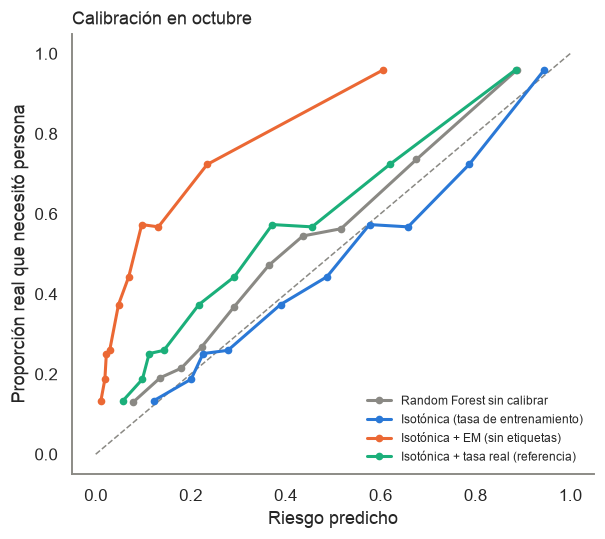

In [9]:
pi_em = estimate_prior_em(p_cal, PRIOR_TR)
p_em, p_oracle = shift_prior(p_cal, PRIOR_TR, pi_em), shift_prior(p_cal, PRIOR_TR, y_te.mean())
print(f"Tasa base: entrenamiento {PRIOR_TR:.3f} | estimada por EM sin etiquetas {pi_em:.3f} | real de octubre {y_te.mean():.3f}")
cal_tab = pd.DataFrame({
    "Random Forest sin calibrar": p_raw, "Isotónica (tasa de entrenamiento)": p_cal,
    "Isotónica + EM (sin etiquetas)": p_em, "Isotónica + tasa real (referencia)": p_oracle})
print(pd.DataFrame({"Brier": cal_tab.apply(lambda p: brier_score_loss(y_te, p)),
                    "riesgo medio predicho": cal_tab.mean()}).round(3))

fig, ax = plt.subplots(figsize=(5.6, 5))
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
for (lab, p), c in zip(cal_tab.items(), [MUTED, C0, C1, C2]):
    fy, fx = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax.plot(fx, fy, marker="o", ms=4, lw=2, color=c, label=lab)
ax.set_xlabel("Riesgo predicho"); ax.set_ylabel("Proporción real que necesitó persona")
ax.set_title("Calibración en octubre", loc="left"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); save(fig, "12_calibracion"); plt.show()

**Resultado: es un cambio de mezcla, no de proporción.**

- **La calibración isotónica sin corregir ya acierta en octubre:** predice un riesgo medio de
  ≈ 46 % cuando el real fue 44 %, y tiene el mejor Brier. El modelo siguió el cambio porque
  reconoce el tipo de operación de cada conversación.
- **La corrección EM falla:** estima una tasa base de ≈ 13 % y empeora mucho la calibración. Ni
  siquiera la tasa real de octubre mejora el resultado. Ambas parten de un supuesto falso (que
  cada conversación se ve igual y solo cambió la proporción) y terminan corrigiendo dos veces.
- El Random Forest sin calibrar, entrenado con pesos balanceados, sí produce probabilidades
  sesgadas; la isotónica las arregla.

**Decisión:** se despliega la probabilidad isotónica **sin corrección por tasa base**. El monitoreo
vigila la calibración **por empresa**, porque la corrección solo se justifica si dentro de una misma
empresa cambia la proporción de casos (por ejemplo, si cambian su operación). Esta hipótesis
quedó escrita en el EDA como riesgo, y aquí se refuta con datos.

## 5. Resultado en octubre con el punto de corte

,ROC-AUC,PR-AUC,azar PR,recall,precisión,% alertado
Octubre,0.786,0.770,0.445,0.623,0.707,0.392
"Octubre, clientes nuevos",0.736,0.784,0.543,0.663,0.700,0.514


Calibración por empresa (riesgo medio predicho vs real):


,n,predicho,real
empresa,,,
E01,1010,0.28,0.22
E12,464,0.59,0.56
E06,427,0.44,0.34
E10,179,0.56,0.84
E07,169,0.91,0.99
E04,109,0.54,0.61
E08,60,0.87,0.95
E02,30,0.94,1.00
E11,17,0.59,0.06


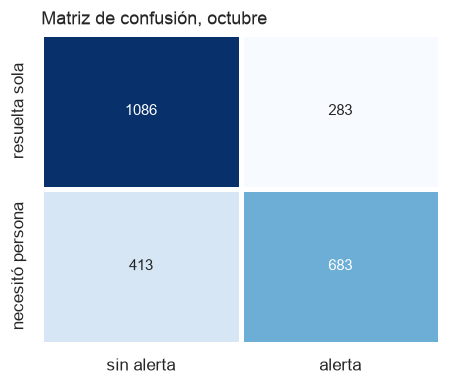

In [10]:
alerta = p_cal >= T_ALERTA
tn, fp, fn, tp = confusion_matrix(y_te, alerta).ravel()
def bloque(y, p, a):
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "azar PR": y.mean(),
            "recall": recall_score(y, a), "precisión": precision_score(y, a), "% alertado": a.mean()}
res_oct = pd.DataFrame({"Octubre": bloque(y_te, p_cal, alerta),
                        "Octubre, clientes nuevos": bloque(y_te[new_cust], p_cal[new_cust], alerta[new_cust])}).T.round(3)
display(res_oct)
print("Calibración por empresa (riesgo medio predicho vs real):")
display(te.assign(p=p_cal).groupby("empresa").agg(n=("p", "size"), predicho=("p", "mean"), real=(TARGET, "mean"))
        .sort_values("n", ascending=False).round(2))
fig, ax = plt.subplots(figsize=(4.2, 3.6))
sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
            xticklabels=["sin alerta", "alerta"], yticklabels=["resuelta sola", "necesitó persona"], ax=ax)
ax.set_title("Matriz de confusión, octubre", loc="left"); fig.tight_layout(); save(fig, "13_confusion"); plt.show()

**El recall de octubre (≈ 0,62) no llega a la meta de 0,80 que se cumplía en validación.** La
razón es el mismo cambio de mezcla. En el entrenamiento, el recall global de 0,80 lo sostenían las
empresas que escalan mucho; en las que escalan poco (como E01), el recall con ese umbral ya era
≈ 0,3. En octubre, E01 pasa a ser el 40 % de las conversaciones y arrastra el promedio.

Bajo *label shift*, el recall con un umbral fijo no cambiaría; aquí sí cambia, y es otra señal de
que el cambio es de mezcla. Se compara la alternativa de **un umbral por empresa**, elegido con las
predicciones fuera de pliegue del entrenamiento, para empresas con al menos 20 positivos y 10
negativos, y el global como respaldo para las demás.

,recall,precisión,% alertado
Umbral global,0.623,0.707,0.392
Umbral por empresa,0.806,0.469,0.763


A posteriori, sobre la curva global de octubre: con recall 0,80 la precisión sería 0.63


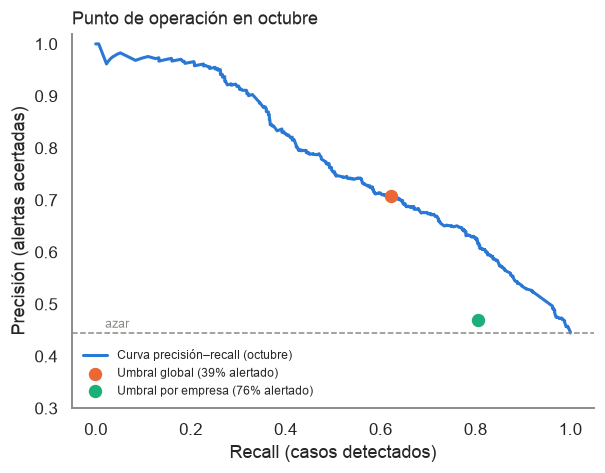

In [11]:
th_emp = {}
for e, g in tr.assign(o=oof).groupby("empresa"):
    if g[TARGET].sum() >= 20 and (1 - g[TARGET]).sum() >= 10:
        th_emp[e] = threshold_for_recall(g[TARGET].values, g.o.values, 0.80)
t_emp = te.empresa.map(th_emp).fillna(T_ALERTA).values
pol = pd.DataFrame({nombre: {"recall": recall_score(y_te, a), "precisión": precision_score(y_te, a), "% alertado": a.mean()}
                    for nombre, a in [("Umbral global", p_cal >= T_ALERTA), ("Umbral por empresa", p_cal >= t_emp)]}).T
display(pol.round(3))
prec_c, rec_c, _ = precision_recall_curve(y_te, p_cal); p_at_80 = prec_c[np.argmin(np.abs(rec_c - 0.80))]
print(f"A posteriori, sobre la curva global de octubre: con recall 0,80 la precisión sería {p_at_80:.2f}")

prec_c, rec_c, _ = precision_recall_curve(y_te, p_cal)
fig, ax = plt.subplots(figsize=(5.6, 4.4))
ax.plot(rec_c, prec_c, color=C0, lw=2, label="Curva precisión–recall (octubre)")
ax.axhline(y_te.mean(), color=MUTED, ls="--", lw=1); ax.text(0.02, y_te.mean() + 0.01, "azar", color=MUTED, fontsize=8)
for (nombre, r), c in zip(pol.iterrows(), [C1, C2]):
    ax.scatter(r["recall"], r["precisión"], color=c, s=60, zorder=3, label=f"{nombre} ({r['% alertado']:.0%} alertado)")
ax.set_xlabel("Recall (casos detectados)"); ax.set_ylabel("Precisión (alertas acertadas)"); ax.set_ylim(0.3, 1.02)
ax.set_title("Punto de operación en octubre", loc="left"); ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout(); save(fig, "13b_politicas_umbral"); plt.show()

Con un umbral por empresa se recupera el recall de 0,80, pero alertando 3 de cada 4
conversaciones con precisión menor a 0,5: en E01, por ejemplo, el umbral queda tan bajo que casi
todo se alerta. Además, ese punto queda **por debajo de la curva global**: bajar el único umbral
global hasta recall 0,80 daría más precisión (≈ 0,6). Con estos datos, los umbrales por empresa no
convienen; su estimación con pocos casos por empresa es ruidosa.

**Decisión de despliegue:**
- **Semáforo con el umbral global.** En octubre detecta 6 de cada 10 casos con 7 de cada 10
  alertas acertadas, y sirve sobre todo para **ordenar la cola** (ver el lift abajo).
- Si el negocio necesita más recall, **se baja el umbral global**, reelegido con los datos del mes
  más reciente durante el monitoreo (3.9), en lugar de fijar umbrales por empresa.

### Métricas de negocio

La alerta se da al **cuarto mensaje**, y por construcción esos 4 mensajes son anteriores a
cualquier intervención humana. Así que cada caso detectado se detecta **antes** de que una persona
del equipo entre a la conversación.

*Limitación honesta:* el conjunto anonimizado no trae cuántos mensajes o minutos después entró la
persona, así que aquí no se puede medir la anticipación exacta. Se agrega como métrica del
monitoreo en producción: el tiempo entre la alerta y el primer mensaje humano.

In [12]:
def top_k(y, p, frac):
    k = int(round(len(p) * frac)); idx = np.argsort(-p)[:k]; return y[idx].mean(), y[idx].sum() / y.sum()
neg = pd.DataFrame({
    "Conversaciones de octubre": len(y_te),
    "Necesitaron persona": int(y_te.sum()),
    "Detectadas al mensaje 4": int(tp),
    "No detectadas": int(fn),
    "Alertas por cada 100 conversaciones": round(100 * alerta.mean(), 1),
    "Alertas acertadas por cada 10": round(10 * tp / (tp + fp), 1),
    "Acertadas por cada 10 si se alertara al azar": round(10 * y_te.mean(), 1),
}, index=["valor"]).T
display(neg)
rows = []
for f in [0.1, 0.2, 0.3]:
    prec, rec = top_k(y_te, p_cal, f)
    rows.append({"revisar primero el": f"{f:.0%} más riesgoso", "precisión": prec, "captura de casos": rec,
                 "lift vs azar": prec / y_te.mean()})
pd.DataFrame(rows).set_index("revisar primero el").round(2)

,valor
Conversaciones de octubre,2465.0
Necesitaron persona,1096.0
Detectadas al mensaje 4,683.0
No detectadas,413.0
Alertas por cada 100 conversaciones,39.2
Alertas acertadas por cada 10,7.1
Acertadas por cada 10 si se alertara al azar,4.4


,precisión,captura de casos,lift vs azar
revisar primero el,,,
10% más riesgoso,0.96,0.22,2.16
20% más riesgoso,0.84,0.38,1.89
30% más riesgoso,0.75,0.51,1.68


### Por empresa
Calidad del orden **dentro** de cada empresa en octubre, y comportamiento del umbral global.

In [13]:
filas = []
for e, g in te.assign(p=p_cal, a=alerta).groupby("empresa"):
    y = g[TARGET].values
    filas.append({"empresa": e, "n": len(g), "% positivos": y.mean(),
                  "ROC-AUC": roc_auc_score(y, g.p) if 0 < y.sum() < len(y) else np.nan,
                  "recall": recall_score(y, g.a) if y.sum() else np.nan,
                  "precisión": precision_score(y, g.a, zero_division=0) if g.a.sum() else np.nan,
                  "% alertado": g.a.mean()})
por_emp = pd.DataFrame(filas).set_index("empresa").sort_values("n", ascending=False)
por_emp.round(2)

,n,% positivos,ROC-AUC,recall,precisión,% alertado
empresa,,,,,,
E01,1010,0.22,0.67,0.30,0.56,0.12
E12,464,0.56,0.58,0.69,0.59,0.65
E06,427,0.34,0.59,0.44,0.47,0.32
E10,179,0.84,0.73,0.58,0.95,0.51
E07,169,0.99,0.74,0.99,0.99,0.99
E04,109,0.61,0.62,0.62,0.71,0.53
E08,60,0.95,0.91,0.95,0.98,0.92
E02,30,1.00,NaN,1.00,1.00,1.00
E11,17,0.06,0.12,0.00,0.00,0.59


- El orden dentro de cada empresa es moderado: AUC entre 0,58 y 0,74 en las empresas con
  suficientes casos, y 0,91 en E08. Buena parte de lo que el modelo sabe es **qué tipo de operación
  tiene cada empresa**, y dentro de ella la señal más fuerte es el **historial del cliente**.
- E11 (17 conversaciones, 1 positiva) y E02 (todas positivas) no permiten medir el orden.
- Con un solo umbral global, las empresas que escalan poco reciben pocas alertas (E01: 12 %) y las
  que escalan casi siempre lo reciben casi todo (E07: 99 %). Para esas últimas la alerta no aporta;
  lo útil es el orden dentro de la cola.

## 6. Explicabilidad con SHAP

SHAP reparte la predicción de cada conversación entre sus variables (valores de Shapley).
Se explica el Random Forest base sin calibrar; la calibración es monótona, así que el orden y la
dirección de los efectos se conservan.

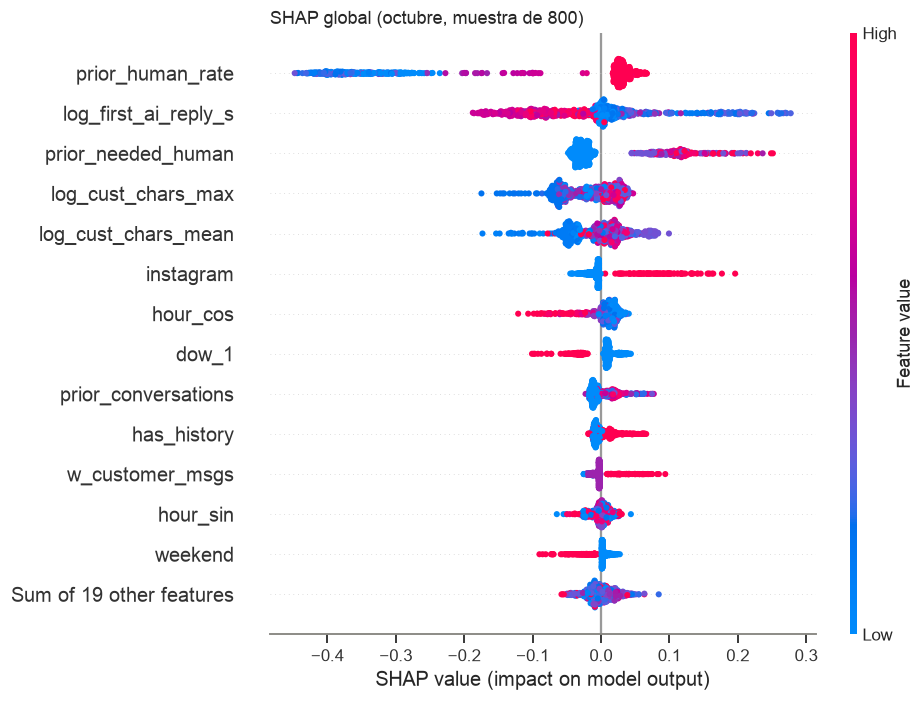

prior_human_rate        0.1483
log_first_ai_reply_s    0.0675
prior_needed_human      0.0565
log_cust_chars_max      0.0343
log_cust_chars_mean     0.0315
instagram               0.0194
hour_cos                0.0168
dow_1                   0.0163
prior_conversations     0.0135
has_history             0.0105
w_customer_msgs         0.0103
hour_sin                0.0096
dtype: float64

In [14]:
sample = te.sample(800, random_state=RNG)
X_s = rf_sin_cal[:-1].transform(build_features(sample, DROP))
expl = shap.TreeExplainer(rf_sin_cal[-1])(X_s)
sv = expl[:, :, 1]
plt.figure(); shap.plots.beeswarm(sv, max_display=14, show=False)
plt.title("SHAP global (octubre, muestra de 800)", loc="left"); save(plt.gcf(), "14_shap_beeswarm"); plt.show()
imp_shap = pd.Series(np.abs(sv.values).mean(0), index=X_s.columns).sort_values(ascending=False)
imp_shap.head(12).round(4)

**Lectura del gráfico.** Cada punto es una conversación. A la derecha, la variable sube el riesgo;
a la izquierda, lo baja. El color es el valor de la variable (rojo alto, azul bajo).

- **El historial del cliente domina.** Si sus conversaciones pasadas se resolvieron solas
  (`prior_human_rate` baja), el riesgo cae mucho; si necesitaron persona, sube. Una vez conocida esa
  proporción, tener más historial suma un poco de riesgo.
- **Tiempo de primera respuesta:** respuestas automáticas lentas se asocian a *menos* riesgo. No es
  causal: refleja qué tipo de automatización usa cada empresa (flujos con espera frente a IA
  inmediata). Es otra huella parcial de la operación.
- **Largo de los mensajes del cliente:** mensajes muy cortos (tocar un botón, un saludo, un «sí»)
  bajan el riesgo; los largos lo suben un poco.
- **Instagram sube el riesgo; lunes y fines de semana lo bajan.** Son efectos pequeños y, en parte,
  de la mezcla de empresas por canal y día.

### `ai_chars_mean` vista con SHAP: una huella de la empresa
Con el modelo que sí la usa, se compara su valor SHAP por empresa.

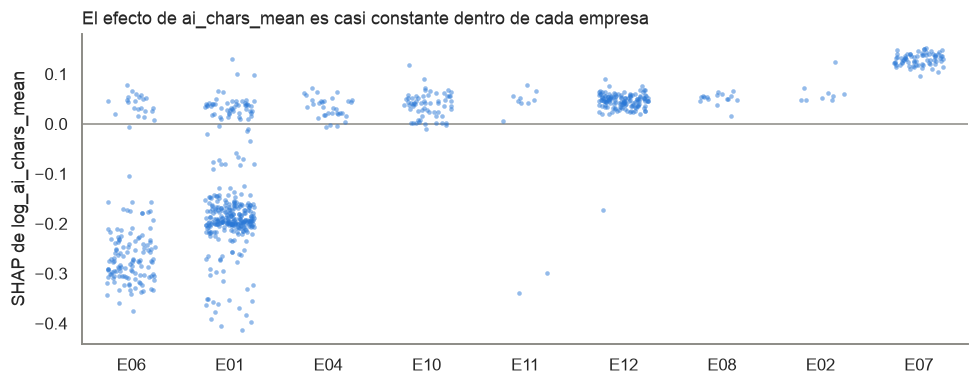

Parte de la varianza del SHAP de ai_chars_mean explicada por la empresa: 67%


In [15]:
rf_con = mejores[("con ai_chars_mean", "Random Forest")]
X_c = rf_con[:-1].transform(build_features(sample, ()))
X_c = pd.DataFrame(X_c, columns=build_features(sample, ()).columns, index=sample.index)
sv_c = shap.TreeExplainer(rf_con[-1])(X_c)[:, :, 1]
col = list(X_c.columns).index("log_ai_chars_mean")
d = pd.DataFrame({"empresa": sample.empresa.values, "shap": sv_c.values[:, col]})
orden_e = d.groupby("empresa").shap.median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.stripplot(data=d, x="empresa", y="shap", order=orden_e, color=C0, size=3, alpha=.5, jitter=.25, ax=ax)
ax.axhline(0, color=MUTED, lw=1); ax.set_ylabel("SHAP de log_ai_chars_mean"); ax.set_xlabel("")
ax.set_title("El efecto de ai_chars_mean es casi constante dentro de cada empresa", loc="left")
fig.tight_layout(); save(fig, "15_shap_ai_chars_empresa"); plt.show()
var_total = d.shap.var(); var_entre = d.groupby("empresa").shap.transform("mean").var()
print(f"Parte de la varianza del SHAP de ai_chars_mean explicada por la empresa: {var_entre / var_total:.0%}")

Casi toda la variación del efecto de `ai_chars_mean` se explica por **qué empresa es**: la variable
le dice al modelo "esta es una empresa que escala poco" o "una que escala mucho". Con SHAP se
confirma lo que el EDA mostró con el AUC dentro de cada empresa, y se justifica dejarla fuera del
modelo desplegado.

### Explicación por predicción
Lo que vería el asesor: el riesgo y las razones principales en lenguaje simple. Los valores SHAP se
agrupan por concepto (por ejemplo, las 4 variables de historial suman una sola razón).


— Conversación de riesgo alto: riesgo 100%, real: necesitó persona
   ▲ De sus 8 conversaciones anteriores, 8 necesitaron a una persona (sube 45 puntos)
   ▲ Sus mensajes son largos (50 caracteres en promedio) (sube 4 puntos)
   ▲ Escribió a las 12:00 (sube 3 puntos)
   ▼ Escribió un lunes (baja 2 puntos)


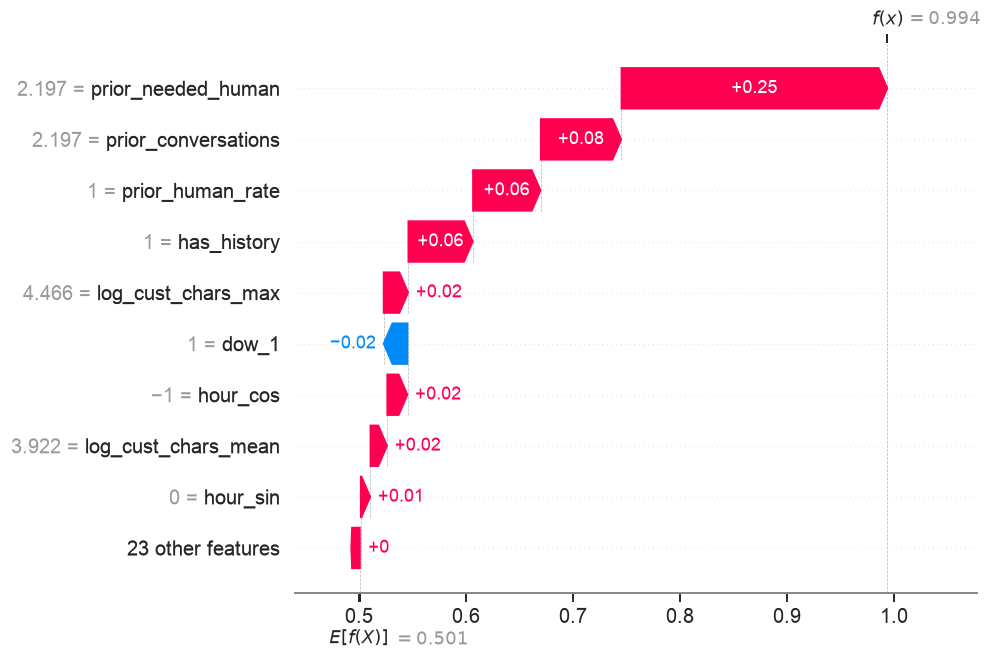


— Conversación cerca del umbral: riesgo 54%, real: necesitó persona
   ▼ Sus mensajes son muy cortos (14 caracteres en promedio) (baja 16 puntos)
   ▲ La primera respuesta automática tardó 6 s (sube 6 puntos)
   ▲ Escribió un miércoles (sube 4 puntos)

— Conversación de riesgo bajo: riesgo 5%, real: resuelta sola
   ▼ Tuvo 1 conversación anterior y no necesitó a una persona (baja 36 puntos)
   ▼ Sus mensajes son muy cortos (12 caracteres en promedio) (baja 14 puntos)
   ▲ La primera respuesta automática tardó 8 s (sube 5 puntos)
   ▲ Escribió a las 13:00 (sube 1 punto)


In [16]:
X_te_t = rf_sin_cal[:-1].transform(Xte_f)
alto = te.index[np.argmax(p_cal)]; bajo = te.index[np.argmin(p_cal)]
medio = te.index[np.argmin(np.abs(p_cal - T_ALERTA))]
for nombre, idx in [("de riesgo alto", alto), ("cerca del umbral", medio), ("de riesgo bajo", bajo)]:
    pos = te.index.get_loc(idx)
    e = shap.TreeExplainer(rf_sin_cal[-1])(X_te_t.iloc[[pos]])[:, :, 1]
    s_row = pd.Series(e.values[0], index=X_te_t.columns)
    print(f"\n— Conversación {nombre}: riesgo {p_cal[pos]:.0%}, real: {'necesitó persona' if y_te[pos] else 'resuelta sola'}")
    for frase, efecto, dir_ in explain(te.loc[idx], s_row):
        print(f"   {'▲' if dir_ == 'sube' else '▼'} {frase} ({dir_} {round(100 * abs(efecto))} punto{'' if round(100 * abs(efecto)) == 1 else 's'})")
    if nombre == "de riesgo alto":
        plt.figure(); shap.plots.waterfall(e[0], max_display=10, show=False)
        save(plt.gcf(), "16_shap_waterfall_alto"); plt.show()

## 7. Modelo final para desplegar

Con los hiperparámetros elegidos, se reentrena con **todas** las conversaciones sin E09
(julio–octubre y las anteriores). Se recalculan los umbrales con predicciones fuera de pliegue
sobre ese mismo conjunto, con las mismas metas de recall (80 % y 95 %). Se guarda:

- `models/riesgo_v1.joblib`: el artefacto `RiskModel` (modelo calibrado, modelo para SHAP,
  umbrales, tasa base de entrenamiento y lista de variables);
- `models/metrics.json`: las métricas que resume `model_card.md`.

In [17]:
final, oof_f = train_risk_model(rest, best_params, meta={"version": "riesgo_v1", "excluye": [DOMINANT]})
th, y_full = final.thresholds, rest[TARGET].values
joblib.dump(final, MODELS / "riesgo_v1.joblib", compress=3)

metrics = {
    "modelo": "Random Forest calibrado (isotónica), sin ai_chars_mean", "params": best_params,
    "umbrales_final": th, "tasa_base_entrenamiento_final": final.prior_train, "meta_final": final.meta,
    "fuera_de_pliegue_final": {"PR-AUC": float(average_precision_score(y_full, oof_f)), "ROC-AUC": float(roc_auc_score(y_full, oof_f)),
                               "recall_alerta": float(recall_score(y_full, oof_f >= th["alerta"])),
                               "precision_alerta": float(precision_score(y_full, oof_f >= th["alerta"])),
                               "pct_alertado": float((oof_f >= th["alerta"]).mean())},
    "octubre": {k: {m: float(v) for m, v in r.items()} for k, r in res_oct.T.to_dict().items()},
    "octubre_umbrales": {"alerta": T_ALERTA, "vigilar": T_VIGILAR},
    "octubre_politicas": {k: {m: float(v) for m, v in r.items()} for k, r in pol.T.to_dict().items()},
    "octubre_tasa_base": {"entrenamiento": float(PRIOR_TR), "em": float(pi_em), "real": float(y_te.mean())},
    "octubre_brier": {k: float(brier_score_loss(y_te, p)) for k, p in cal_tab.items()},
    "comparacion": R.drop(columns="params").round(4).to_dict(orient="records"),
    "por_empresa_octubre": por_emp.round(4).reset_index().to_dict(orient="records"),
    "negocio_octubre": {k: (int(v) if float(v).is_integer() else float(v)) for k, v in neg["valor"].items()},
}
json.dump(metrics, open(MODELS / "metrics.json", "w"), indent=2, ensure_ascii=False, default=float)
print(json.dumps({k: metrics[k] for k in ["umbrales_final", "tasa_base_entrenamiento_final", "fuera_de_pliegue_final"]}, indent=2))

check = joblib.load(MODELS / "riesgo_v1.joblib").risk(te.head(5))
check

{
  "umbrales_final": {
    "alerta": 0.467235298035298,
    "vigilar": 0.295403798616978
  },
  "tasa_base_entrenamiento_final": 0.5532157085941947,
  "fuera_de_pliegue_final": {
    "PR-AUC": 0.848015929323543,
    "ROC-AUC": 0.8147066190197432,
    "recall_alerta": 0.8000685871056241,
    "precision_alerta": 0.7392268694550064,
    "pct_alertado": 0.5987478656801366
  }
}


,score,riesgo,nivel
0,0.281755,0.281755,verde
2,0.443758,0.443758,amarillo
3,0.454022,0.454022,amarillo
6,0.151626,0.151626,verde
7,0.058441,0.058441,verde


## 8. Conclusiones

1. **Modelo elegido: Random Forest calibrado con isotónica, sin `ai_chars_mean`.** En octubre
   (datos nunca vistos, un mes posterior) logra **ROC-AUC 0,79 y PR-AUC 0,77, contra 0,44 al azar**.
   Con clientes nuevos, ROC-AUC 0,74. Con empresas nunca vistas, 0,69.
2. **Generaliza en el tiempo, con límites claros para negocios nuevos.** La curva de aprendizaje
   sigue subiendo, así que más meses y más empresas deberían mejorar el modelo.
3. **Quitar la huella de la empresa cuesta 0,02 de PR-AUC y no cambia nada dentro de cada empresa.**
   SHAP confirma que el 67 % de la variación del efecto de `ai_chars_mean` es la identidad de la
   empresa.
4. **Lo que más pesa es el historial del cliente**, seguido del tiempo de primera respuesta y del
   largo de sus mensajes.
5. **El cambio de octubre es de mezcla de empresas, no de proporción.** La probabilidad calibrada ya
   lo sigue (46 % predicho contra 44 % real), y la corrección por tasa base lo empeora. Se despliega
   sin corrección y se vigila la calibración por empresa.
6. **Punto de operación.** Con el umbral global, en octubre se detectan **6 de cada 10 casos** al
   cuarto mensaje, antes de cualquier intervención humana, y **7 de cada 10 alertas son correctas**,
   contra 4,4 al azar. Mirando primero el 10 % más riesgoso, 96 % de esas conversaciones
   necesitaron persona. La meta de recall 0,80 de la validación no se sostuvo en octubre por el
   cambio de mezcla. Para recuperarla conviene bajar el umbral global (precisión ≈ 0,6), no fijar
   umbrales por empresa, que quedan por debajo de la curva.
7. **El techo es la información, no el algoritmo:** dentro de cada empresa todos los modelos se
   quedan en AUC ≈ 0,64. El siguiente salto vendría de ampliar la ventana (hasta 8 mensajes), de
   señales de texto más ricas y de medir cuándo entró la persona, para cuantificar la anticipación.